# **Little Minds**
### Classifying Happiness and Sadness in Children’s Drawings

## Introduction

Children use drawings to express ideas and emotions through choices such as color, shapes, and composition. These visual choices can vary widely across children, even when they are drawing in response to the same prompt. Little Minds AI explores whether a computer vision model can learn patterns across this variation and use them to distinguish between drawings that depict happiness and sadness.

We use a convolutional neural network (CNN) to learn visual features directly from the images. We also compare models trained on color and grayscale versions of the same drawings to investigate how much color contributes to classification. This comparison helps us understand which visual information supports the model’s predictions and where the two themes are difficult to distinguish.

## Problem Statement

Given a drawing, the model predicts whether it was intended to represent **happiness** or **sadness**. The goal is to learn visual patterns that generalize to drawings from students whose work was held out during training.

## Dataset

[KIDO Children Drawings Dataset on Kaggle](https://www.kaggle.com/datasets/serdarciftci/kido-children-drawing-dataset/data)

## Methodology

1. **Explore the data.** Verify image files, labels, and student IDs. Examine class distributions and sample drawings.
2. **Prepare the images.** Check KIDO’s provided train/test split for student overlap, then create a validation set from the training data using student IDs. Resize and normalize the drawings.
3. **Train and compare CNNs.** Train a baseline on color images and repeat the experiment with grayscale images using the same architecture, splits, and training settings.
4. **Evaluate the results.** Compare models using validation macro-F1. Evaluate the selected model on the held-out test set and review its confusion matrix and classification errors.
5. **Deploy a demo.** Build a Streamlit app that accepts a drawing and displays its predicted theme.


## Prepared by

**Fay · Ghadi · Lulwa · Mohammed · Abdullah**

## **1. Import librares**

In [1]:
# File handling and data quality.
import hashlib
from collections import Counter
from pathlib import Path

# Dataset download.
import kagglehub

# Data exploration and visualization.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

# Data splitting and model evaluation.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

# Model building and training.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

## **2. Data Loading and understanding**

In [2]:
# Download KIDO and save the dataset folder path.
DATA_DIR = Path(kagglehub.dataset_download("serdarciftci/kido-children-drawing-dataset"))

# Show where the dataset was downloaded.
print("Dataset location:", DATA_DIR)

Using Colab cache for faster access to the 'kido-children-drawing-dataset' dataset.
Dataset location: /kaggle/input/kido-children-drawing-dataset


In [3]:
# Show all folders and subfolders without listing files.
for folder in sorted(DATA_DIR.rglob("*")):
    if folder.is_dir():
        print(folder.relative_to(DATA_DIR))


Dataset
Dataset/Images
Dataset/Images/Education
Dataset/Images/Education/test
Dataset/Images/Education/test/Primary
Dataset/Images/Education/test/Secondary
Dataset/Images/Education/train
Dataset/Images/Education/train/Primary
Dataset/Images/Education/train/Secondary
Dataset/Images/Emotion
Dataset/Images/Emotion/test
Dataset/Images/Emotion/test/Happiness
Dataset/Images/Emotion/test/Sadness
Dataset/Images/Emotion/train
Dataset/Images/Emotion/train/Happiness
Dataset/Images/Emotion/train/Sadness
Dataset/Images/Gender
Dataset/Images/Gender/test
Dataset/Images/Gender/test/Female
Dataset/Images/Gender/test/Male
Dataset/Images/Gender/train
Dataset/Images/Gender/train/Female
Dataset/Images/Gender/train/Male
Dataset/Texts
Dataset/Texts/Education
Dataset/Texts/Emotion
Dataset/Texts/Gender


In [4]:
# Set the path to the emotion drawings.
EMOTION_DIR = DATA_DIR / "Dataset" / "Images" / "Emotion"
image_extensions = {".jpg", ".jpeg", ".png"}

# Count images in each split and class.
for split in ["train", "test"]:
    for label in ["Happiness", "Sadness"]:
        folder = EMOTION_DIR / split / label
        count = sum(
            path.is_file() and path.suffix.lower() in image_extensions
            for path in folder.iterdir()
        )
        print(f"{split}/{label}: {count:,} images")

train/Happiness: 4,614 images
train/Sadness: 4,614 images
test/Happiness: 816 images
test/Sadness: 816 images


In [5]:
# Collect the training image paths.
train_images = sorted(
    path for path in (EMOTION_DIR / "train").rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
)

# Check the sizes and color modes of the first 20 images.
image_sizes = Counter()
color_modes = Counter()

for path in train_images[:20]:
    with Image.open(path) as image:
        image_sizes[image.size] += 1
        color_modes[image.mode] += 1

print("Image sizes:", dict(image_sizes))
print("Color modes:", dict(color_modes))

Image sizes: {(512, 362): 20}
Color modes: {'RGB': 20}


In [6]:
# Find images that cannot be opened or are corrupt.
corrupt_images = []

for path in EMOTION_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        try:
            with Image.open(path) as image:
                image.verify()
        except (OSError, ValueError):
            corrupt_images.append(path)

print("Corrupt images:", len(corrupt_images))

Corrupt images: 0


In [7]:
# Find images with identical file contents.
image_hashes = {}
duplicates = []

for path in EMOTION_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        file_hash = hashlib.sha256(path.read_bytes()).hexdigest()

        if file_hash in image_hashes:
            duplicates.append((image_hashes[file_hash], path))
        else:
            image_hashes[file_hash] = path

print("Exact duplicate files:", len(duplicates))

Exact duplicate files: 0


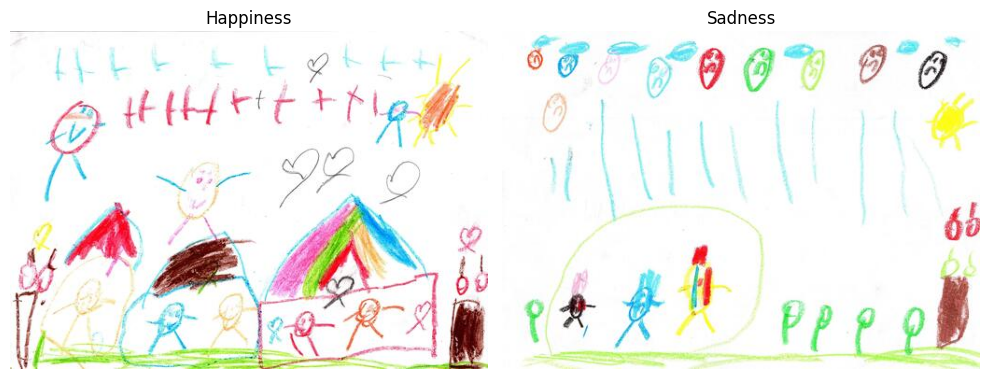

In [8]:
# Show one training drawing from each class.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, label in zip(axes, ["Happiness", "Sadness"]):
    path = next(path for path in train_images if path.parent.name == label)

    with Image.open(path) as image:
        ax.imshow(image)

    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

- The project uses KIDO’s Emotion images, labeled **Happiness** and **Sadness**.
- The provided training and test sets are balanced, with **4,614 images per class** for training and **816 per class** for testing.
- All 20 sampled training images were **512 × 362 pixels** and **RGB**.

## **3. EDA**

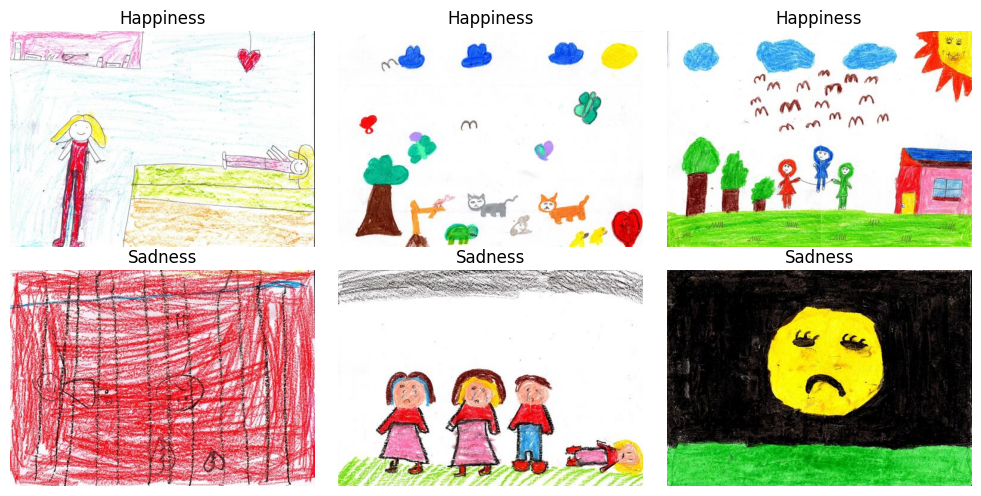

In [9]:
# Select three random training drawings per class.
rng = np.random.default_rng(42)
labels = ["Happiness", "Sadness"]
fig, axes = plt.subplots(2, 3, figsize=(10, 5))

# Display one row of drawings per class.
for row, label in enumerate(labels):
    paths = [path for path in train_images if path.parent.name == label]
    sample_paths = rng.choice(paths, size=3, replace=False)

    for ax, path in zip(axes[row], sample_paths):
        with Image.open(path) as image:
            ax.imshow(image)
        ax.set_title(label)
        ax.axis("off")

plt.tight_layout()
plt.show()

 The drawings  use facial expressions, shading, and scene details to convey their themes. These six examples suggest that color is worth investigating across a larger set of training images

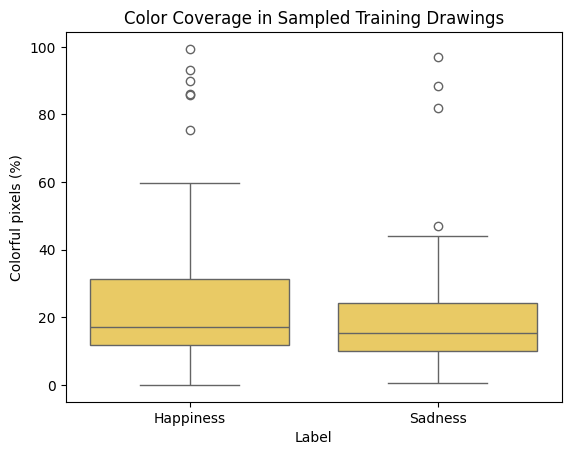

In [10]:
# Measure colorful pixel coverage in 100 training drawings per class.
rng = np.random.default_rng(42)
color_results = []

for label in ["Happiness", "Sadness"]:
    paths = [path for path in train_images if path.parent.name == label]

    for path in rng.choice(paths, size=100, replace=False):
        with Image.open(path) as image:
            pixels = np.asarray(image.convert("RGB"), dtype=np.int16)

        channel_range = pixels.max(axis=2) - pixels.min(axis=2)
        colorful_percent = (channel_range > 40).mean() * 100

        color_results.append({
            "Label": label,
            "Colorful pixels (%)": colorful_percent,
        })

# Compare the distribution of color coverage across classes.
color_df = pd.DataFrame(color_results)
sns.boxplot(data=color_df, x="Label", y="Colorful pixels (%)", color="#FFD54F")
plt.title("Color Coverage in Sampled Training Drawings")
plt.show()

In the sampled training drawings, Happiness had a slightly higher median color coverage than Sadness

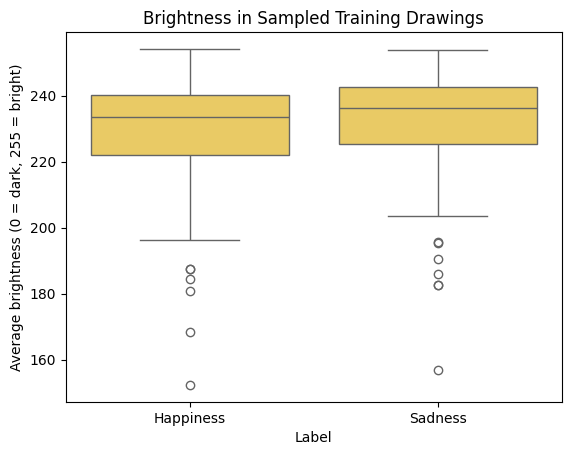

In [11]:
# Measure average brightness for 100 training drawings per class.
rng = np.random.default_rng(42)
brightness_results = []

for label in ["Happiness", "Sadness"]:
    paths = [path for path in train_images if path.parent.name == label]

    for path in rng.choice(paths, size=100, replace=False):
        with Image.open(path) as image:
            grayscale = np.asarray(image.convert("L"))

        brightness_results.append({
            "Label": label,
            "Average brightness": grayscale.mean()
        })

# Compare brightness across the two classes.
brightness_df = pd.DataFrame(brightness_results)

sns.boxplot(
    data=brightness_df,
    x="Label",
    y="Average brightness",
    color="#FFD54F"
)

plt.title("Brightness in Sampled Training Drawings")
plt.ylabel("Average brightness (0 = dark, 255 = bright)")
plt.show()

The sampled Sadness drawings have a slightly higher median brightness than the Happiness drawings

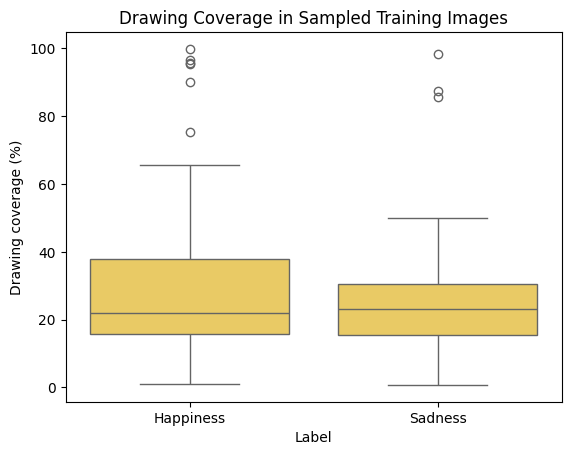

In [12]:
# Estimate drawing coverage for 100 training images per class.
rng = np.random.default_rng(42)
coverage_results = []

for label in ["Happiness", "Sadness"]:
    paths = [path for path in train_images if path.parent.name == label]

    for path in rng.choice(paths, size=100, replace=False):
        with Image.open(path) as image:
            grayscale = np.asarray(image.convert("L"))

        coverage = (grayscale < 240).mean() * 100

        coverage_results.append({
            "Label": label,
            "Drawing coverage (%)": coverage
        })

# Compare estimated drawing coverage across the two classes.
coverage_df = pd.DataFrame(coverage_results)

sns.boxplot(
    data=coverage_df,
    x="Label",
    y="Drawing coverage (%)",
    color="#FFD54F"
)

plt.title("Drawing Coverage in Sampled Training Images")
plt.show()

The sampled Happiness and Sadness drawings have similar median coverage and Happiness shows more variation

The distributions overlap substantially, suggesting that no single visual measure clearly separates the classes. These findings are based on samples of 100 training images per class.

## 4. **Data Preparation**

### 4.1 Check Student Overlap

In [13]:
# Loop through train and test folders
for split in ["train", "test"]:

    # Loop through both emotions
    for label in ["Happiness", "Sadness"]:

        # Get the folder path
        folder = EMOTION_DIR / split / label

        # Get the first 3 images
        sample_files = sorted(
            path for path in folder.iterdir()
            if path.suffix.lower() in image_extensions
        )[:3]

        # Print the folder name
        print(f"\n{split} / {label}")

        # Print image names
        for path in sample_files:
            print(path.name)



train / Happiness
101-1A-1240-M-H.jpg
101-1A-1298-M-H.jpg
101-1A-141-M-H.jpg

train / Sadness
101-1A-1240-M-S.jpg
101-1A-1298-M-S.jpg
101-1A-141-M-S.jpg

test / Happiness
101-1A-369-F-H.jpg
101-1B-102-M-H.jpg
101-1B-212-F-H.jpg

test / Sadness
101-1A-369-F-S.jpg
101-1B-102-M-S.jpg
101-1B-212-F-S.jpg


We checked the image names and noticed that each student has two drawings, one for Happiness and one for Sadness. We can use the filename to identify each student.

In [14]:

# Extract student IDs and check for overlap

# Get student ID without the emotion label
def get_student_id(path):
    return path.stem.rsplit("-", 1)[0]

# Store student IDs from each split
student_ids = {}

for split in ["train", "test"]:

    # Get all images from the split
    images = [
        path for path in (EMOTION_DIR / split).rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    ]

    # Get unique student IDs
    student_ids[split] = {
        get_student_id(path) for path in images
    }

    print(f"{split}: {len(student_ids[split])} students")

# Check if students appear in both splits
overlap = student_ids["train"] & student_ids["test"]

print(f"\nStudents in both splits: {len(overlap)}")
print("Sample overlap:", sorted(overlap)[:5])


train: 4614 students
test: 816 students

Students in both splits: 0
Sample overlap: []


We found 4614 students in train and 816 in test. There are no students shared between them, so we don't have student overlap.

## 4.2 Create the Validation Split

In [15]:

# Split training data by student ID

# Get student IDs for training images
groups = [get_student_id(path) for path in train_images]

# Keep 20% of students for validation
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

# Split students into train and validation
train_idx, val_idx = next(
    splitter.split(train_images, groups=groups)
)

# Get image paths for each split
train_paths = [train_images[i] for i in train_idx]
val_paths = [train_images[i] for i in val_idx]

# Get student IDs for each split
train_students = {get_student_id(p) for p in train_paths}
val_students = {get_student_id(p) for p in val_paths}

# Check the results
print("Train images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Train students:", len(train_students))
print("Validation students:", len(val_students))
print("Student overlap:", len(train_students & val_students))


Train images: 7382
Validation images: 1846
Train students: 3691
Validation students: 923
Student overlap: 0


We split the original training set by student ID, using 80% of the students for training and 20% for validation. No student IDs overlap between the two groups.

In [16]:

# Save student IDs for each dataset split

# Get test student IDs
test_students = student_ids["test"]

# Make sure there is no student overlap
assert not (train_students & val_students)
assert not (train_students & test_students)
assert not (val_students & test_students)

# Create a table with student IDs and their split
split_df = pd.DataFrame(
    [(sid, "train") for sid in sorted(train_students)] +
    [(sid, "validation") for sid in sorted(val_students)] +
    [(sid, "test") for sid in sorted(test_students)],
    columns=["student_id", "split"]
)

# Save the table as a CSV file
SPLITS_PATH = Path("student_splits.csv")
split_df.to_csv(SPLITS_PATH, index=False)

# Check the saved results
print("Saved to:", SPLITS_PATH)
print("\nStudents per split:")
print(split_df["split"].value_counts())
print("\nTotal students:", len(split_df))


Saved to: student_splits.csv

Students per split:
split
train         3691
validation     923
test           816
Name: count, dtype: int64

Total students: 5430


We saved the student IDs and their groups in a CSV file. We have 5430 students in total, and each student belongs to only one group.

### 4.3 Encode Labels

In [17]:

# Set the class names
class_names = ["Happiness", "Sadness"]

# Give each class a number
label_to_id = {"Happiness": 0, "Sadness": 1}

# Get all test image paths
test_paths = sorted(
    path for path in (EMOTION_DIR / "test").rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
)

# Get the label for each image
def get_labels(paths):
    return [label_to_id[path.parent.name] for path in paths]

# Create labels for each split
train_labels = get_labels(train_paths)
val_labels = get_labels(val_paths)
test_labels = get_labels(test_paths)

# Check the image counts and labels
print("Class names:", class_names)
print("Label mapping:", label_to_id)

print("\nTrain:", len(train_paths), Counter(train_labels))
print("Validation:", len(val_paths), Counter(val_labels))
print("Test:", len(test_paths), Counter(test_labels))


Class names: ['Happiness', 'Sadness']
Label mapping: {'Happiness': 0, 'Sadness': 1}

Train: 7382 Counter({0: 3691, 1: 3691})
Validation: 1846 Counter({0: 923, 1: 923})
Test: 1632 Counter({0: 816, 1: 816})


We gave Happiness the label 0 and Sadness the label 1. We checked the numbers and found that both classes are balanced in all three datasets.

### 4.4 Resize and Normalize Images

In [18]:
# Set the image size and batch size.
IMG_SIZE = (180, 256)
BATCH_SIZE = 32

# Load, resize, and normalize one image.
def preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

We resized the images to 180x256 and changed the pixel values to 0-1. We tested one image and got the correct shape and pixel range.

### 4.5 Create TensorFlow Datasets

In [19]:
# Create a dataset from image paths and labels.
def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        ([str(path) for path in paths], labels)
    )

    # Shuffle the training data.
    if training:
        dataset = dataset.shuffle(len(paths), seed=42)

    # Prepare images and group them into batches.
    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    return dataset.prefetch(tf.data.AUTOTUNE)


# Create the training, validation, and test datasets.
train_ds = create_dataset(train_paths, train_labels, training=True)
val_ds = create_dataset(val_paths, val_labels)
test_ds = create_dataset(test_paths, test_labels)


# Check one training batch.
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Image batch shape: (32, 180, 256, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0




- Images were resized to **180 × 256** pixels and normalized to a **0–1** range.
- Happiness was encoded as **0** and Sadness as **1**.
- The data was grouped into batches of **32 images**.
- Student IDs do not overlap across the train, validation, and test sets.

## **5. Baseline CNN**

In [20]:
# Build the baseline CNN.
baseline_model = keras.Sequential([
    layers.Input(shape=(180, 256, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

# Display the model architecture.
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 127, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 125, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 38400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,457,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,514,049 (9.59 MB)

 Trainable params: 2,514,049 (9.59 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Configure the model for binary classification.
baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Stop when validation loss stops improving.
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the baseline CNN.
baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 38s 115ms/step - accuracy: 0.5792 - loss: 0.6842 - val_accuracy: 0.5850 - val_loss: 0.6744
Epoch 2/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 13s 57ms/step - accuracy: 0.6074 - loss: 0.6665 - val_accuracy: 0.6289 - val_loss: 0.6568
Epoch 3/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.6347 - loss: 0.6496 - val_accuracy: 0.6089 - val_loss: 0.6693
Epoch 4/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 13s 57ms/step - accuracy: 0.6387 - loss: 0.6323 - val_accuracy: 0.6327 - val_loss: 0.6477
Epoch 5/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.6803 - loss: 0.5912 - val_accuracy: 0.6295 - val_loss: 0.6666
Epoch 6/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.7212 - loss: 0.5409 - val_accuracy: 0.6148 - val_loss: 0.6708
Epoch 7/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 13s 57ms/step - accuracy: 0.7735 - loss: 0.4662 - val_accuracy: 0.6257 - val_loss: 0.7498


In [22]:
# Collect validation predictions and their matching labels.
val_true = []
baseline_predictions = []

for images, labels in val_ds:
    scores = baseline_model(images, training=False).numpy().ravel()
    baseline_predictions.extend((scores >= 0.5).astype(int))
    val_true.extend(labels.numpy())

# Calculate validation results.
baseline_loss, baseline_accuracy = baseline_model.evaluate(val_ds, verbose=0)
baseline_f1 = f1_score(val_true, baseline_predictions, average="macro")

print(f"Validation accuracy: {baseline_accuracy:.4f}")
print(f"Validation macro-F1: {baseline_f1:.4f}")
print(f"Validation loss: {baseline_loss:.4f}")

Validation accuracy: 0.6327
Validation macro-F1: 0.6327
Validation loss: 0.6477


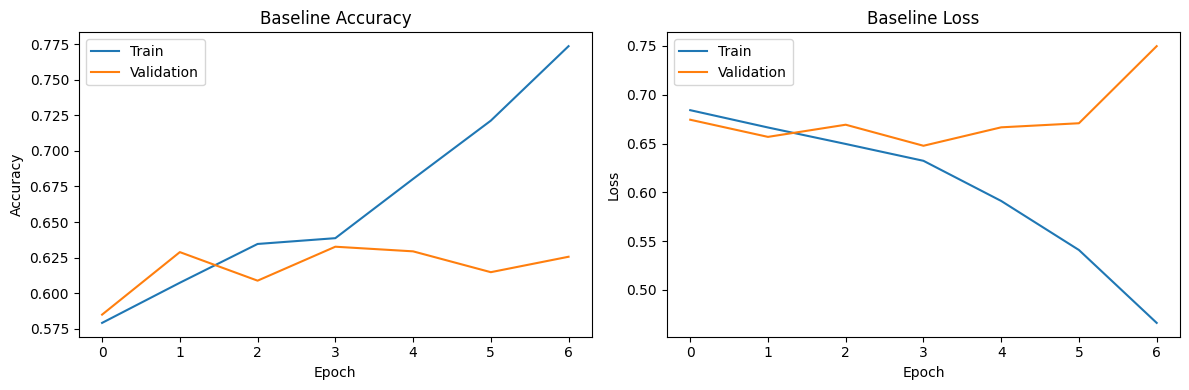

In [23]:
# Plot training and validation accuracy.
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(baseline_history.history["accuracy"], label="Train")
plt.plot(baseline_history.history["val_accuracy"], label="Validation")
plt.title("Baseline Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot training and validation loss.
plt.subplot(1, 2, 2)
plt.plot(baseline_history.history["loss"], label="Train")
plt.plot(baseline_history.history["val_loss"], label="Validation")
plt.title("Baseline Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## **6. Transfer Learning: MobileNetV2**

In [24]:
# Load the pretrained MobileNetV2 backbone.
mobile_backbone = keras.applications.MobileNetV2(
    input_shape=(180, 256, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the backbone during the first training stage.
mobile_backbone.trainable = False

# Build the MobileNetV2 classification model.
inputs = keras.Input(shape=(180, 256, 3))

# Convert normalized pixels from 0–1 to -1–1.
x = layers.Rescaling(2, offset=-1)(inputs)
x = mobile_backbone(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

mobile_model = keras.Model(inputs, outputs)

# Display the model architecture.
mobile_model.summary()

/tmp/ipykernel_1713/416015169.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobile_backbone = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 180, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 8, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [25]:
# Configure MobileNetV2 for binary classification.
mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Restore the weights with the lowest validation loss.
mobile_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the classification layers.
mobile_history = mobile_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[mobile_stop]
)

Epoch 1/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 59s 153ms/step - accuracy: 0.6054 - loss: 0.7015 - val_accuracy: 0.6593 - val_loss: 0.6281
Epoch 2/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.6604 - loss: 0.6340 - val_accuracy: 0.6701 - val_loss: 0.6188
Epoch 3/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.6788 - loss: 0.6010 - val_accuracy: 0.6782 - val_loss: 0.6165
Epoch 4/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.6892 - loss: 0.5913 - val_accuracy: 0.6701 - val_loss: 0.6204
Epoch 5/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 60ms/step - accuracy: 0.6940 - loss: 0.5838 - val_accuracy: 0.6934 - val_loss: 0.6018
Epoch 6/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.6974 - loss: 0.5798 - val_accuracy: 0.6950 - val_loss: 0.5987
Epoch 7/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.7025 - loss: 0.5746 - val_accuracy: 0.6966 - val_loss: 0.5994
Epoch 8/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.6947 - loss: 0.5750 -

In [26]:
# Collect validation predictions and their matching labels.
mobile_true = []
mobile_predictions = []

for images, labels in val_ds:
    scores = mobile_model(images, training=False).numpy().ravel()
    mobile_predictions.extend((scores >= 0.5).astype(int))
    mobile_true.extend(labels.numpy())

# Calculate validation metrics.
mobile_loss, mobile_accuracy = mobile_model.evaluate(val_ds, verbose=0)
mobile_f1 = f1_score(mobile_true, mobile_predictions, average="macro")

print(f"Validation accuracy: {mobile_accuracy:.4f}")
print(f"Validation macro-F1: {mobile_f1:.4f}")
print(f"Validation loss: {mobile_loss:.4f}")

Validation accuracy: 0.6950
Validation macro-F1: 0.6950
Validation loss: 0.5987


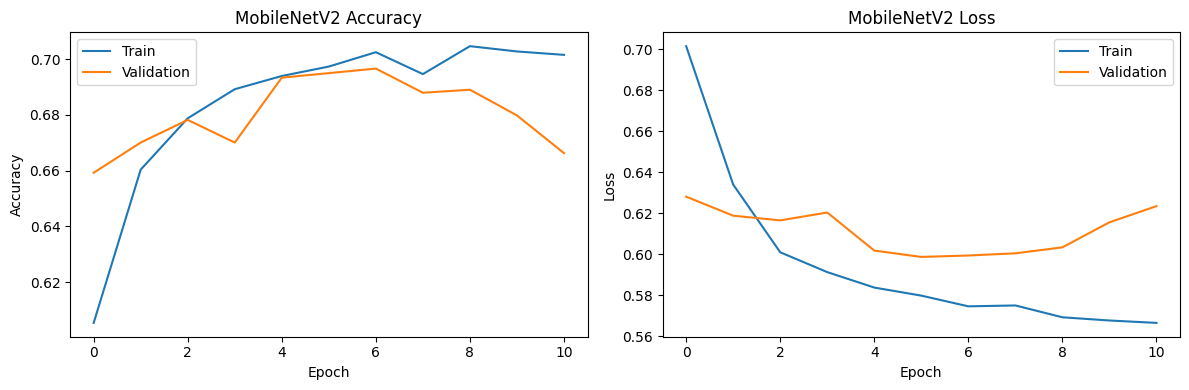

In [27]:
# Plot training and validation accuracy.
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(mobile_history.history["accuracy"], label="Train")
plt.plot(mobile_history.history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot training and validation loss.
plt.subplot(1, 2, 2)
plt.plot(mobile_history.history["loss"], label="Train")
plt.plot(mobile_history.history["val_loss"], label="Validation")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 7. **Fine-Tuning MobileNetV2**

In [28]:
# Save the frozen MobileNetV2 weights.
mobile_model.save_weights("mobilenet_frozen.weights.h5")

# Unfreeze the last 30 backbone layers.
mobile_backbone.trainable = True

for layer in mobile_backbone.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen.
for layer in mobile_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a smaller learning rate.
mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

mobile_fine_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Fine-tune MobileNetV2.
mobile_fine_history = mobile_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[mobile_fine_stop]
)

# Save the fine-tuned weights.
mobile_model.save_weights("mobilenet_fine_tuned.weights.h5")

Epoch 1/15
231/231 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - accuracy: 0.7029 - loss: 0.5701 - val_accuracy: 0.6977 - val_loss: 0.5935
Epoch 2/15
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 60ms/step - accuracy: 0.7258 - loss: 0.5391 - val_accuracy: 0.6853 - val_loss: 0.5988
Epoch 3/15
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 61ms/step - accuracy: 0.7513 - loss: 0.5100 - val_accuracy: 0.7021 - val_loss: 0.5882
Epoch 4/15
231/231 ━━━━━━━━━━━━━━━━━━━━ 21s 62ms/step - accuracy: 0.7563 - loss: 0.4911 - val_accuracy: 0.7069 - val_loss: 0.5822
Epoch 5/15
231/231 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.7753 - loss: 0.4653 - val_accuracy: 0.7129 - val_loss: 0.5849
Epoch 6/15
231/231 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.7973 - loss: 0.4377 - val_accuracy: 0.7172 - val_loss: 0.5899
Epoch 7/15
231/231 ━━━━━━━━━━━━━━━━━━━━ 23s 72ms/step - accuracy: 0.8089 - loss: 0.4228 - val_accuracy: 0.7031 - val_loss: 0.5927


In [29]:
# Collect validation predictions and their matching labels.
mobile_fine_true = []
mobile_fine_predictions = []

for images, labels in val_ds:
    scores = mobile_model(images, training=False).numpy().ravel()
    mobile_fine_predictions.extend((scores >= 0.5).astype(int))
    mobile_fine_true.extend(labels.numpy())

# Calculate validation metrics after fine-tuning.
mobile_fine_loss, mobile_fine_accuracy = mobile_model.evaluate(
    val_ds, verbose=0
)
mobile_fine_f1 = f1_score(
    mobile_fine_true,
    mobile_fine_predictions,
    average="macro"
)

print(f"Validation accuracy: {mobile_fine_accuracy:.4f}")
print(f"Validation macro-F1: {mobile_fine_f1:.4f}")
print(f"Validation loss: {mobile_fine_loss:.4f}")

Validation accuracy: 0.7069
Validation macro-F1: 0.7067
Validation loss: 0.5822


In [ ]:
# Create a separate MobileNetV2 model for the new experiment.
enhanced_mobile = keras.models.clone_model(mobile_model)
enhanced_mobile.load_weights("mobilenet_frozen.weights.h5")

# Find the MobileNetV2 backbone inside the model.
enhanced_backbone = next(
    layer for layer in enhanced_mobile.layers
    if isinstance(layer, keras.Model)
    and "mobilenet" in layer.name.lower()
)

# Unfreeze the last 60 backbone layers.
enhanced_backbone.trainable = True

for layer in enhanced_backbone.layers[:-60]:
    layer.trainable = False

# Keep BatchNormalization layers frozen.
for layer in enhanced_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Compile with a small learning rate.
enhanced_mobile.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Stop when validation loss stops improving.
enhanced_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Fine-tune the model.
enhanced_history = enhanced_mobile.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[enhanced_stop]
)

# Collect validation predictions and labels.
enhanced_true = []
enhanced_predictions = []

for images, labels in val_ds:
    scores = enhanced_mobile(images, training=False).numpy().ravel()
    enhanced_predictions.extend((scores >= 0.5).astype(int))
    enhanced_true.extend(labels.numpy())

# Calculate validation metrics.
enhanced_loss, enhanced_accuracy = enhanced_mobile.evaluate(
    val_ds, verbose=0
)

enhanced_f1 = f1_score(
    enhanced_true,
    enhanced_predictions,
    average="macro"
)

print(f"\nValidation accuracy: {enhanced_accuracy:.4f}")
print(f"Validation macro-F1: {enhanced_f1:.4f}")
print(f"Validation loss: {enhanced_loss:.4f}")

# Save the experiment weights.
enhanced_mobile.save_weights("mobilenet_60_layers.weights.h5")

In [31]:
# Ensemble: average the predictions of the two fine-tuned MobileNetV2 models.
mobile_model.load_weights("mobilenet_fine_tuned.weights.h5")

# The cloned model has the same name as the original, so give each a unique name.
for m, new_name in [(mobile_model, "mobilenet_30_layers"), (enhanced_mobile, "mobilenet_60_layers")]:
    try:
        m.name = new_name
    except AttributeError:
        m._name = new_name

ens_inputs = keras.Input(shape=(180, 256, 3))
ens_outputs = layers.Average()([mobile_model(ens_inputs), enhanced_mobile(ens_inputs)])
ensemble_model = keras.Model(ens_inputs, ens_outputs, name="mobilenet_ensemble")
ensemble_model.compile(loss="binary_crossentropy", metrics=["accuracy"])

# Validation metrics, same method as the other models.
ensemble_true, ensemble_predictions = [], []
for images, labels in val_ds:
    scores = ensemble_model(images, training=False).numpy().ravel()
    ensemble_predictions.extend((scores >= 0.5).astype(int))
    ensemble_true.extend(labels.numpy())

ensemble_loss, ensemble_accuracy = ensemble_model.evaluate(val_ds, verbose=0)
ensemble_f1 = f1_score(ensemble_true, ensemble_predictions, average="macro")

print(f"Validation accuracy: {ensemble_accuracy:.4f}")
print(f"Validation macro-F1: {ensemble_f1:.4f}")
print(f"Validation loss: {ensemble_loss:.4f}")

Validation accuracy: 0.7161
Validation macro-F1: 0.7161
Validation loss: 0.5800


### 7.2 Extra MobileNetV2 Experiments

Two more versions of MobileNetV2, both with light augmentation (small rotation and zoom) on the training images:

-  the same as the 60-layer model above, with augmentation added inside the mode
-  10 frozen epochs, then the last 30 layers fine-tuned for 10 epochs


In [32]:
# Light augmentation, only active during training.
augment = keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
], name="augmentation")

# Same MobileNetV2 setup as before, with augmentation at the start.
aug_backbone = keras.applications.MobileNetV2(
    input_shape=(180, 256, 3), include_top=False, weights="imagenet"
)
aug_backbone.trainable = False

inputs = keras.Input(shape=(180, 256, 3))
x = augment(inputs)
x = layers.Rescaling(2, offset=-1)(x)
x = aug_backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
aug_model = keras.Model(inputs, outputs)

# Stage 1: train the head only.
aug_model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss="binary_crossentropy", metrics=["accuracy"])
aug_model.fit(train_ds, validation_data=val_ds, epochs=20,
              callbacks=[keras.callbacks.EarlyStopping(
                  monitor="val_loss", patience=5, restore_best_weights=True)])

# Stage 2: fine-tune the last 60 layers, BatchNorm stays frozen.
aug_backbone.trainable = True
for layer in aug_backbone.layers[:-60]:
    layer.trainable = False
for layer in aug_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

aug_model.compile(optimizer=keras.optimizers.Adam(0.00001),
                  loss="binary_crossentropy", metrics=["accuracy"])
aug_model.fit(train_ds, validation_data=val_ds, epochs=15,
              callbacks=[keras.callbacks.EarlyStopping(
                  monitor="val_loss", patience=3, restore_best_weights=True)])

aug_model.save_weights("mobilenet_aug.weights.h5")

# Validation results.
aug_true, aug_predictions = [], []
for images, labels in val_ds:
    scores = aug_model(images, training=False).numpy().ravel()
    aug_predictions.extend((scores >= 0.5).astype(int))
    aug_true.extend(labels.numpy())

aug_loss, aug_accuracy = aug_model.evaluate(val_ds, verbose=0)
aug_f1 = f1_score(aug_true, aug_predictions, average="macro")

print(f"Validation accuracy: {aug_accuracy:.4f}")
print(f"Validation macro-F1: {aug_f1:.4f}")
print(f"Validation loss: {aug_loss:.4f}")

/tmp/ipykernel_1713/1045065358.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  aug_backbone = keras.applications.MobileNetV2(


Epoch 1/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 27s 83ms/step - accuracy: 0.6011 - loss: 0.7058 - val_accuracy: 0.6701 - val_loss: 0.6203
Epoch 2/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 16s 69ms/step - accuracy: 0.6432 - loss: 0.6477 - val_accuracy: 0.6625 - val_loss: 0.6261
Epoch 3/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 19s 80ms/step - accuracy: 0.6696 - loss: 0.6125 - val_accuracy: 0.6712 - val_loss: 0.6043
Epoch 4/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.6754 - loss: 0.6078 - val_accuracy: 0.6815 - val_loss: 0.6160
Epoch 5/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 21s 74ms/step - accuracy: 0.6784 - loss: 0.6025 - val_accuracy: 0.6771 - val_loss: 0.6012
Epoch 6/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.6800 - loss: 0.5959 - val_accuracy: 0.6858 - val_loss: 0.6017
Epoch 7/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 21s 71ms/step - accuracy: 0.6817 - loss: 0.5941 - val_accuracy: 0.6739 - val_loss: 0.6117
Epoch 8/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 23s 82ms/step - accuracy: 0.6869 - loss: 0.5916 - 

In [33]:
# Same MobileNetV2 setup as the final notebook (final_v2).

# Light augmentation on the training images only.
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05)
])
train_ds_aug = train_ds.map(
    lambda images, labels: (data_augmentation(images, training=True), labels),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

# Pretrained MobileNetV2, frozen first.
v2_backbone = keras.applications.MobileNetV2(
    input_shape=(180, 256, 3), include_top=False, weights="imagenet"
)
v2_backbone.trainable = False

v2_model = keras.Sequential([
    layers.Input(shape=(180, 256, 3)),
    layers.Rescaling(2.0, offset=-1.0),
    v2_backbone,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

# Stage 1: train the head only.
v2_model.compile(optimizer=keras.optimizers.Adam(0.001),
                 loss="binary_crossentropy", metrics=["accuracy"])
v2_model.fit(train_ds_aug, validation_data=val_ds, epochs=10,
             callbacks=[keras.callbacks.EarlyStopping(
                 monitor="val_loss", patience=5, restore_best_weights=True)])

# Stage 2: fine-tune the last 30 layers.
v2_backbone.trainable = True
for layer in v2_backbone.layers[:-30]:
    layer.trainable = False

v2_model.compile(optimizer=keras.optimizers.Adam(0.00001),
                 loss="binary_crossentropy", metrics=["accuracy"])
v2_model.fit(train_ds_aug, validation_data=val_ds, epochs=10,
             callbacks=[keras.callbacks.EarlyStopping(
                 monitor="val_loss", patience=5, restore_best_weights=True)])

# Validation results.
v2_true, v2_predictions = [], []
for images, labels in val_ds:
    scores = v2_model(images, training=False).numpy().ravel()
    v2_predictions.extend((scores >= 0.5).astype(int))
    v2_true.extend(labels.numpy())

v2_loss, v2_accuracy = v2_model.evaluate(val_ds, verbose=0)
v2_f1 = f1_score(v2_true, v2_predictions, average="macro")

print(f"Validation accuracy: {v2_accuracy:.4f}")
print(f"Validation macro-F1: {v2_f1:.4f}")
print(f"Validation loss: {v2_loss:.4f}")

/tmp/ipykernel_1713/585343899.py:14: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  v2_backbone = keras.applications.MobileNetV2(


Epoch 1/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 79s 298ms/step - accuracy: 0.6128 - loss: 0.6962 - val_accuracy: 0.6506 - val_loss: 0.6392
Epoch 2/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 60s 260ms/step - accuracy: 0.6585 - loss: 0.6264 - val_accuracy: 0.6555 - val_loss: 0.6288
Epoch 3/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 80s 254ms/step - accuracy: 0.6734 - loss: 0.6091 - val_accuracy: 0.6641 - val_loss: 0.6183
Epoch 4/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 59s 255ms/step - accuracy: 0.6749 - loss: 0.6036 - val_accuracy: 0.6717 - val_loss: 0.6135
Epoch 5/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 60s 256ms/step - accuracy: 0.6757 - loss: 0.6048 - val_accuracy: 0.6690 - val_loss: 0.6120
Epoch 6/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 59s 254ms/step - accuracy: 0.6868 - loss: 0.5911 - val_accuracy: 0.6674 - val_loss: 0.6123
Epoch 7/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 83s 257ms/step - accuracy: 0.6845 - loss: 0.5958 - val_accuracy: 0.6750 - val_loss: 0.6053
Epoch 8/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 59s 253ms/step - accuracy: 0.6803 - loss: 0

## 8. **Model Comparison**


In [37]:
# Compare all models on the validation set.
comparison_df = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Accuracy": baseline_accuracy,
        "Macro-F1": baseline_f1,
        "Loss": baseline_loss
    },
    {
        "Model": "MobileNetV2 Frozen",
        "Accuracy": mobile_accuracy,
        "Macro-F1": mobile_f1,
        "Loss": mobile_loss
    },
    {
        "Model": "MobileNetV2 Fine-tuned",
        "Accuracy": mobile_fine_accuracy,
        "Macro-F1": mobile_fine_f1,
        "Loss": mobile_fine_loss
    },

    {
        "Model": "MobileNetV2 60-layer Fine-tuned",
        "Accuracy": enhanced_accuracy,
        "Macro-F1": enhanced_f1,
        "Loss": enhanced_loss
        },

    {
        "Model": "MobileNetV2 Ensemble (30 + 60 layers)",
        "Accuracy": ensemble_accuracy,
        "Macro-F1": ensemble_f1,
        "Loss": ensemble_loss
    },

    {
        "Model": "MobileNetV2 60 + Augmentation",
        "Accuracy": aug_accuracy,
        "Macro-F1": aug_f1,
        "Loss": aug_loss
    },

    {
        "Model": "MobileNetV2 ",
        "Accuracy": v2_accuracy,
        "Macro-F1": v2_f1,
        "Loss": v2_loss
    }

])

# Sort the models by validation macro-F1.
comparison_df = comparison_df.sort_values(
    "Macro-F1",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Accuracy,Macro-F1,Loss
0,MobileNetV2 60 + Augmentation,0.7264,0.7264,0.5560
1,MobileNetV2 60-layer Fine-tuned,0.7205,0.7205,0.5813
2,MobileNetV2 Ensemble (30 + 60 layers),0.7161,0.7161,0.5800
3,MobileNetV2 Fine-tuned,0.7069,0.7067,0.5822
4,MobileNetV2,0.6977,0.6976,0.5998
5,MobileNetV2 Frozen,0.6950,0.6950,0.5987
6,Baseline CNN,0.6327,0.6327,0.6477


## 9. **Final Model Evaluation**

Selected model: MobileNetV2 60 + Augmentation
Validation macro-F1: 0.7264

Test accuracy: 0.7059
Test macro-F1: 0.7058
Test loss: 0.5705

Classification Report
              precision    recall  f1-score   support

   Happiness     0.7005    0.7194    0.7098       816
     Sadness     0.7116    0.6924    0.7019       816

    accuracy                         0.7059      1632
   macro avg     0.7060    0.7059    0.7058      1632
weighted avg     0.7060    0.7059    0.7058      1632



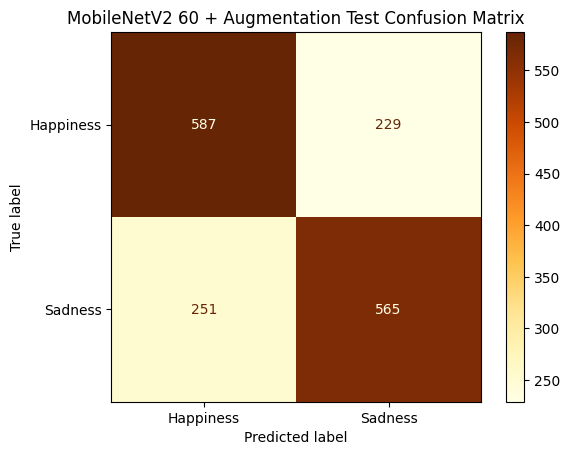

In [35]:
# Select the model with the highest validation macro-F1.
best_name = comparison_df.iloc[0]["Model"]

if best_name == "Baseline CNN":
    final_model = baseline_model

elif best_name == "MobileNetV2 Frozen":
    # Load the weights from before fine-tuning.
    mobile_model.load_weights("mobilenet_frozen.weights.h5")
    final_model = mobile_model

elif best_name == "MobileNetV2 Fine-tuned":
    # Load the fine-tuned weights.
    mobile_model.load_weights("mobilenet_fine_tuned.weights.h5")
    final_model = mobile_model

elif best_name == "MobileNetV2 60-layer Fine-tuned":
    final_model = enhanced_mobile

elif best_name == "MobileNetV2 Ensemble (30 + 60 layers)":
    final_model = ensemble_model

elif best_name == "MobileNetV2 60 + Augmentation":
    final_model = aug_model

elif best_name == "MobileNetV2 (final_v2 setup)":
    final_model = v2_model

else:
    raise ValueError(f"Unknown model: {best_name}")

print("Selected model:", best_name)
print("Validation macro-F1:", round(comparison_df.iloc[0]["Macro-F1"], 4))


# Collect test predictions and matching labels.
test_true = []
test_predictions = []

for images, labels in test_ds:
    scores = final_model(images, training=False).numpy().ravel()
    test_predictions.extend((scores >= 0.5).astype(int))
    test_true.extend(labels.numpy())


# Calculate test accuracy and macro-F1.
test_loss, test_accuracy = final_model.evaluate(test_ds, verbose=0)
test_f1 = f1_score(test_true, test_predictions, average="macro")

print(f"\nTest accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_f1:.4f}")
print(f"Test loss: {test_loss:.4f}")


# Show precision, recall, and F1 for each class.
print("\nClassification Report")
print(classification_report(
    test_true,
    test_predictions,
    target_names=["Happiness", "Sadness"],
    digits=4
))


# Display the confusion matrix.
ConfusionMatrixDisplay.from_predictions(
    test_true,
    test_predictions,
    display_labels=["Happiness", "Sadness"],
    cmap="YlOrBr"
)

plt.title(f"{best_name} Test Confusion Matrix")
plt.show()

We also tested two changes on the validation set that need no retraining:

- **Threshold tuning**: the best threshold on validation was 0.5, so we kept 0.5.
- **Flip test-time augmentation**: averaging each drawing with its mirror image lowered validation macro-F1 (0.7049 vs 0.7149), so we did not use it.

In [36]:
import json

final_model.save("final_model.keras")

app_config = {
    "model_name": best_name,
    "img_size": [180, 256],
    "pixel_range": "0-1",
    "threshold": 0.5,
    "label_order": ["Happiness", "Sadness"],
    "test_macro_f1": round(float(test_f1), 4),
}
with open("app_config.json", "w") as f:
    json.dump(app_config, f, indent=2)
print(app_config)

{'model_name': 'MobileNetV2 60 + Augmentation', 'img_size': [180, 256], 'pixel_range': '0-1', 'threshold': 0.5, 'label_order': ['Happiness', 'Sadness'], 'test_macro_f1': 0.7058}


## Additional Experiment: Color vs. Grayscale

During EDA, we explored the color coverage of the drawings. In this
experiment, we investigate whether removing color changes model
performance. We use the same data splits, model architecture, and
training settings for both versions.

### Prepare Grayscale Images

In [39]:
# Convert RGB images to grayscale while keeping three channels.
def make_grayscale(images, labels):
    images = tf.image.rgb_to_grayscale(images)
    images = tf.image.grayscale_to_rgb(images)
    return images, labels


# Create grayscale versions of the training and validation datasets.
train_gray = train_ds.map(
    make_grayscale,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

val_gray = val_ds.map(
    make_grayscale,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

### Build the Model

In [40]:
# Build MobileNetV2 with the same architecture for both experiments.
def build_color_experiment_model():
    backbone = keras.applications.MobileNetV2(
        input_shape=(180, 256, 3),
        include_top=False,
        weights="imagenet"
    )
    backbone.trainable = False

    inputs = keras.Input(shape=(180, 256, 3))
    x = layers.Rescaling(2, offset=-1)(inputs)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs)
    return model, backbone

### Train and Evaluate

In [41]:
# Train and evaluate one version of the experiment.
def run_color_experiment(train_data, val_data, image_type):

    # Use the same starting seed for each model.
    keras.utils.set_random_seed(42)
    model, backbone = build_color_experiment_model()

    # Train the classification head.
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    print(f"\nTraining on {image_type} images...")
    model.fit(
        train_data,
        validation_data=val_data,
        epochs=20,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )]
    )

    # Fine-tune the last 60 layers and keep BatchNormalization frozen.
    backbone.trainable = True

    for layer in backbone.layers[:-60]:
        layer.trainable = False

    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.00001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        train_data,
        validation_data=val_data,
        epochs=15,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )]
    )

    # Collect validation predictions and matching labels.
    true_labels = []
    predictions = []

    for images, labels in val_data:
        scores = model(images, training=False).numpy().ravel()
        predictions.extend((scores >= 0.5).astype(int))
        true_labels.extend(labels.numpy().ravel())

    # Calculate validation metrics.
    loss, accuracy = model.evaluate(val_data, verbose=0)
    macro_f1 = f1_score(true_labels, predictions, average="macro")

    return model, {
        "Images": image_type,
        "Validation accuracy": accuracy,
        "Validation macro-F1": macro_f1,
        "Validation loss": loss
    }

### Run Both Experiments

In [42]:
# Train and evaluate the color model.
color_model, color_results = run_color_experiment(
    train_ds, val_ds, "Color"
)

# Train and evaluate the grayscale model.
gray_model, gray_results = run_color_experiment(
    train_gray, val_gray, "Grayscale"
)

/tmp/ipykernel_1713/1645329551.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = keras.applications.MobileNetV2(



Training on Color images...
Epoch 1/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 58s 194ms/step - accuracy: 0.5988 - loss: 0.7141 - val_accuracy: 0.6528 - val_loss: 0.6291
Epoch 2/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 45s 63ms/step - accuracy: 0.6620 - loss: 0.6326 - val_accuracy: 0.6723 - val_loss: 0.6170
Epoch 3/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.6701 - loss: 0.6103 - val_accuracy: 0.6815 - val_loss: 0.6070
Epoch 4/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.6746 - loss: 0.5971 - val_accuracy: 0.6896 - val_loss: 0.6027
Epoch 5/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.6995 - loss: 0.5798 - val_accuracy: 0.6858 - val_loss: 0.6049
Epoch 6/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 58ms/step - accuracy: 0.6886 - loss: 0.5805 - val_accuracy: 0.6826 - val_loss: 0.6053
Epoch 7/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.6905 - loss: 0.5812 - val_accuracy: 0.6863 - val_loss: 0.6044
Epoch 8/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accu

/tmp/ipykernel_1713/1645329551.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = keras.applications.MobileNetV2(



Training on Grayscale images...
Epoch 1/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 37s 124ms/step - accuracy: 0.5818 - loss: 0.7335 - val_accuracy: 0.6192 - val_loss: 0.6494
Epoch 2/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step - accuracy: 0.6436 - loss: 0.6467 - val_accuracy: 0.6544 - val_loss: 0.6444
Epoch 3/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - accuracy: 0.6540 - loss: 0.6228 - val_accuracy: 0.6674 - val_loss: 0.6178
Epoch 4/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - accuracy: 0.6653 - loss: 0.6173 - val_accuracy: 0.6598 - val_loss: 0.6197
Epoch 5/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 20s 84ms/step - accuracy: 0.6726 - loss: 0.6082 - val_accuracy: 0.6647 - val_loss: 0.6116
Epoch 6/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 21s 89ms/step - accuracy: 0.6799 - loss: 0.5969 - val_accuracy: 0.6701 - val_loss: 0.6111
Epoch 7/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy: 0.6750 - loss: 0.5997 - val_accuracy: 0.6663 - val_loss: 0.6090
Epoch 8/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 22s 90ms/step - 

In [44]:
# Compare color and grayscale validation results.
color_comparison = pd.DataFrame([color_results, gray_results])
display(color_comparison.round(4))

,Images,Validation accuracy,Validation macro-F1,Validation loss
0,Color,0.7183,0.7180,0.5756
1,Grayscale,0.6950,0.6947,0.5854


### Compare the Results

## **10. Conclusion**

In this project, we explored the KIDO children’s drawings dataset
and developed deep learning models to classify drawings into
Happiness and Sadness categories.

We began by examining the dataset structure and checking image
quality. During exploratory data analysis, we visualized sample
drawings and compared color coverage, brightness, and drawing
coverage across the two categories. The distributions overlapped,
suggesting that no single visual characteristic clearly separates
the classes.

We prepared the images by resizing and normalizing them. We also
checked that no student appeared in more than one data split. This
helped us evaluate the models on drawings from students whose work
was not used during training.

All team members contributed to exploratory analysis and modeling.
We trained a baseline CNN and experimented with MobileNetV2 using
transfer learning and fine-tuning. We compared the models using
validation macro-F1 and selected **MobileNetV2 60 + Augmentation**, which achieved a
validation macro-F1 of **0.7264**.


As an additional experiment inspired by our EDA, we compared color
and grayscale drawings using the same model settings. The color
model achieved a validation macro-F1 of 71.80%, while the grayscale
model achieved 69.47%. This suggests The color model performed slightly better

Overall, the project shows that a deep learning model can learn
visual patterns associated with the dataset’s drawing labels.
However, a drawing alone cannot establish a child’s actual emotional
state, and this model should not be used for psychological diagnosis.